# Follow-up questions, reported apart (KAN-228)
Gözde Nur Özdemir · ELIZA · Sprint 3

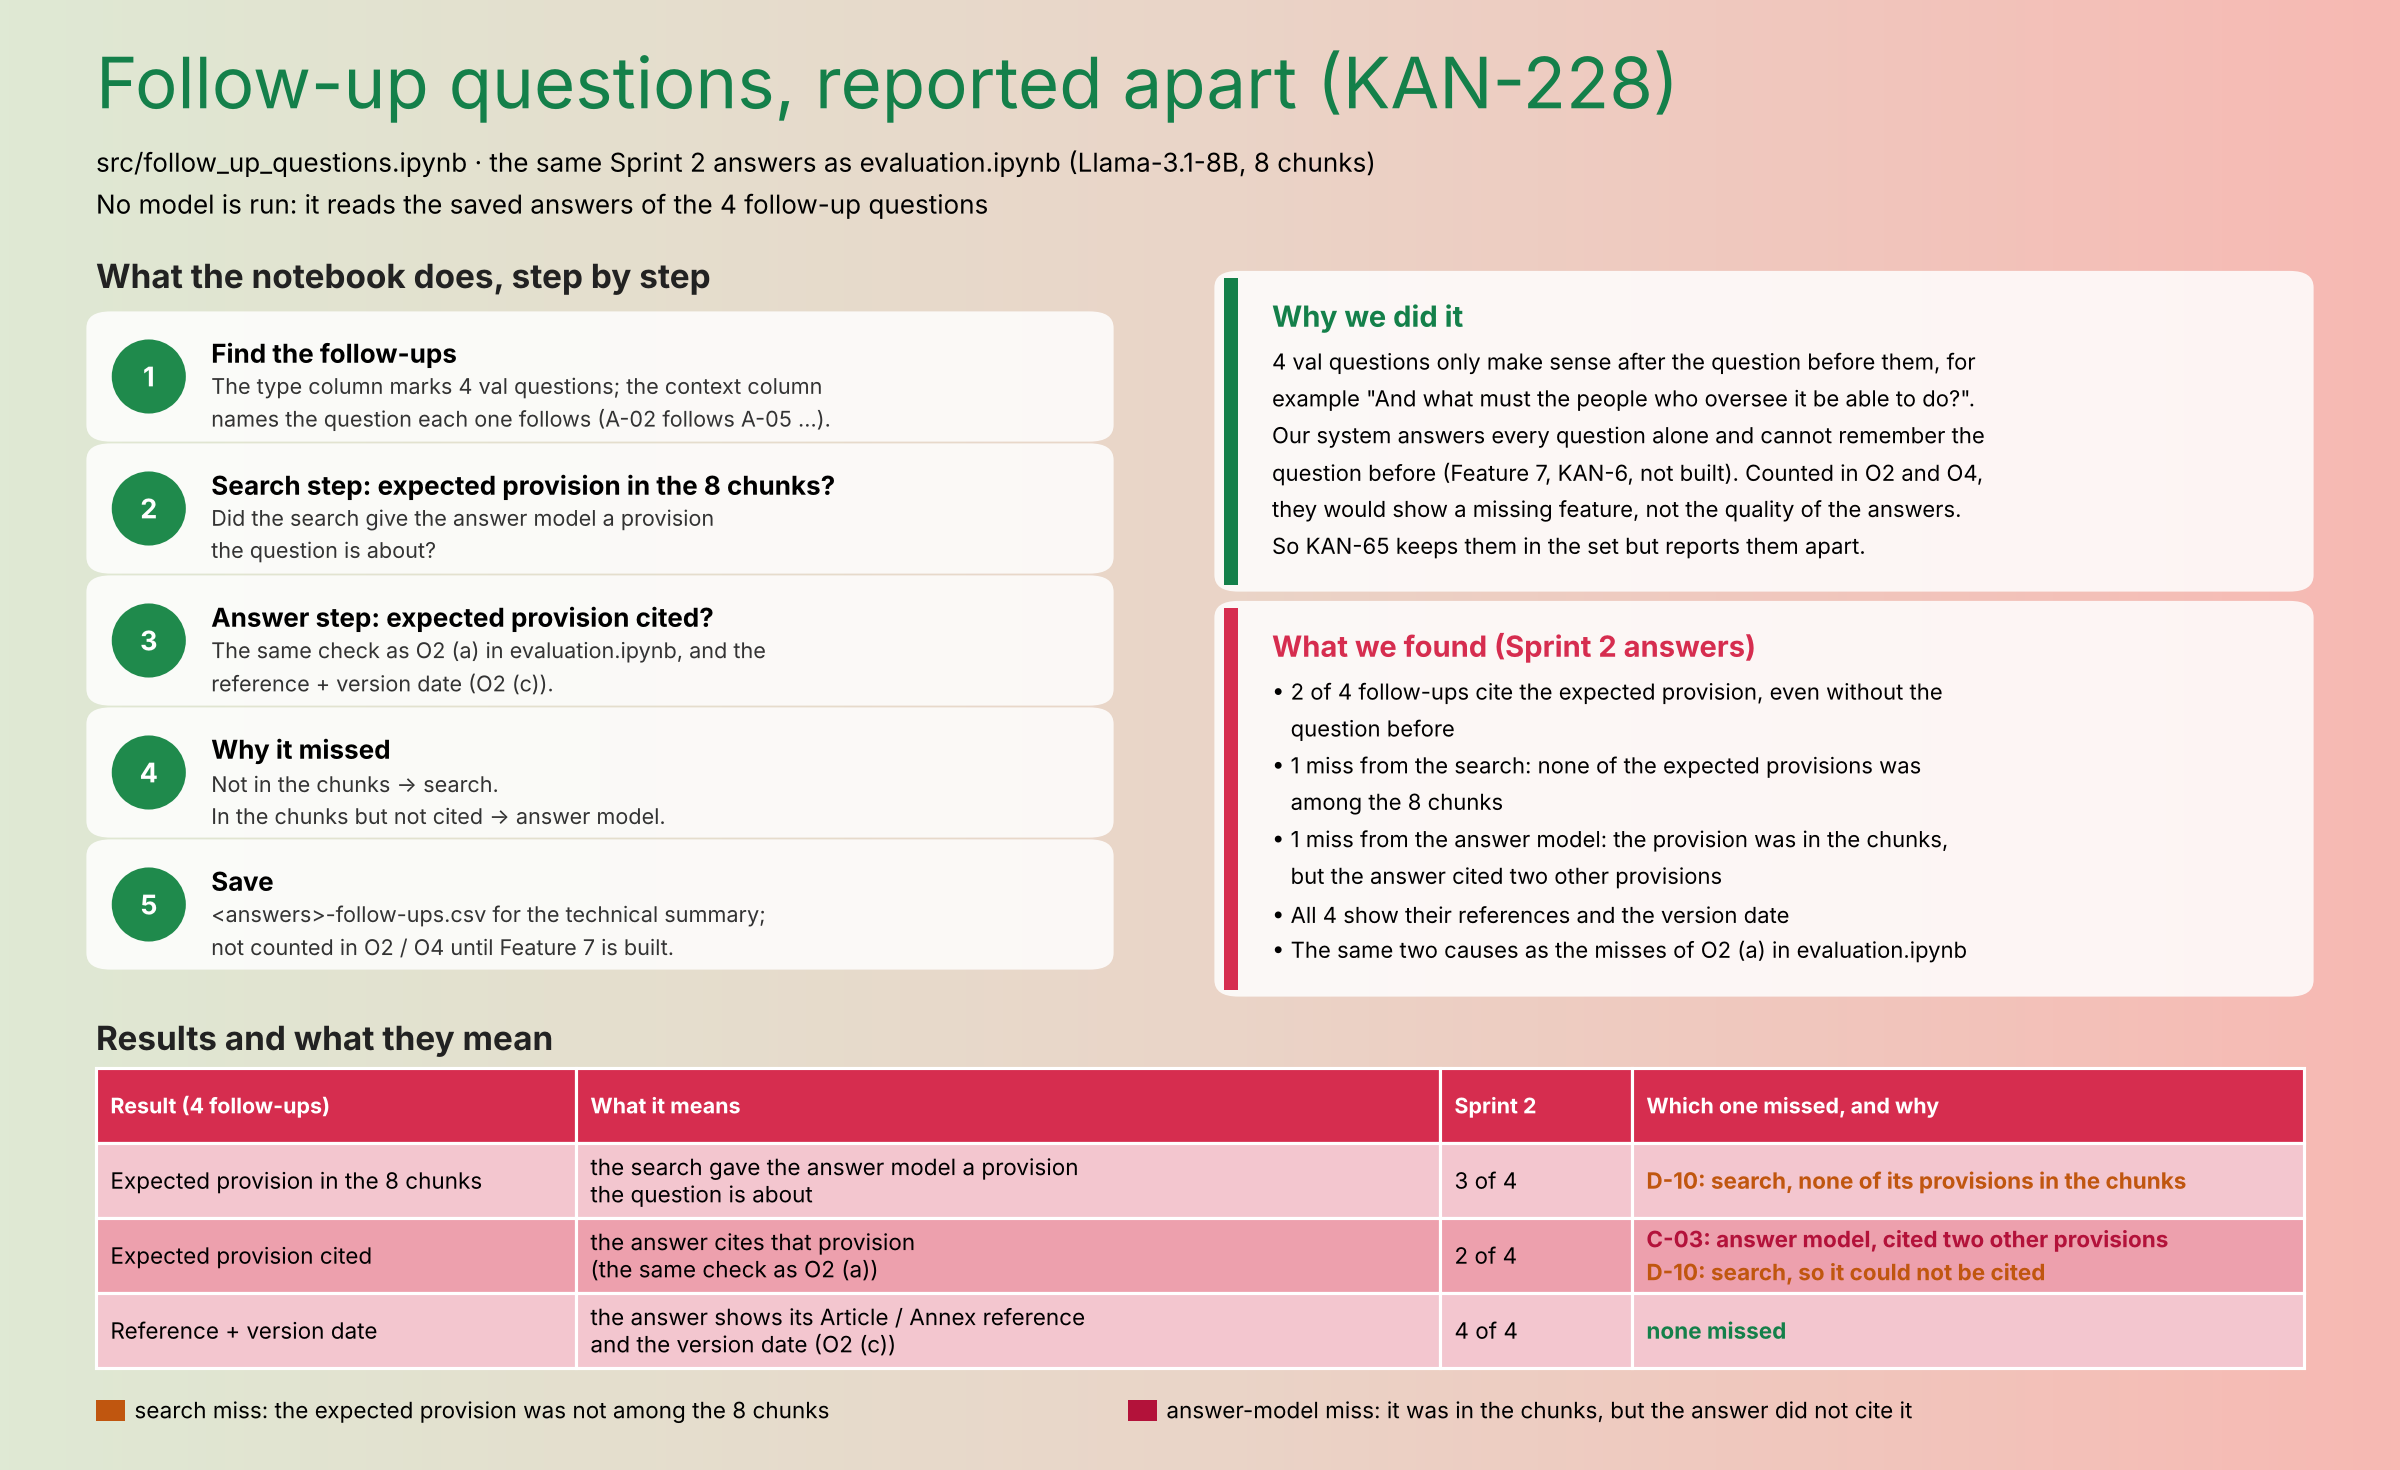

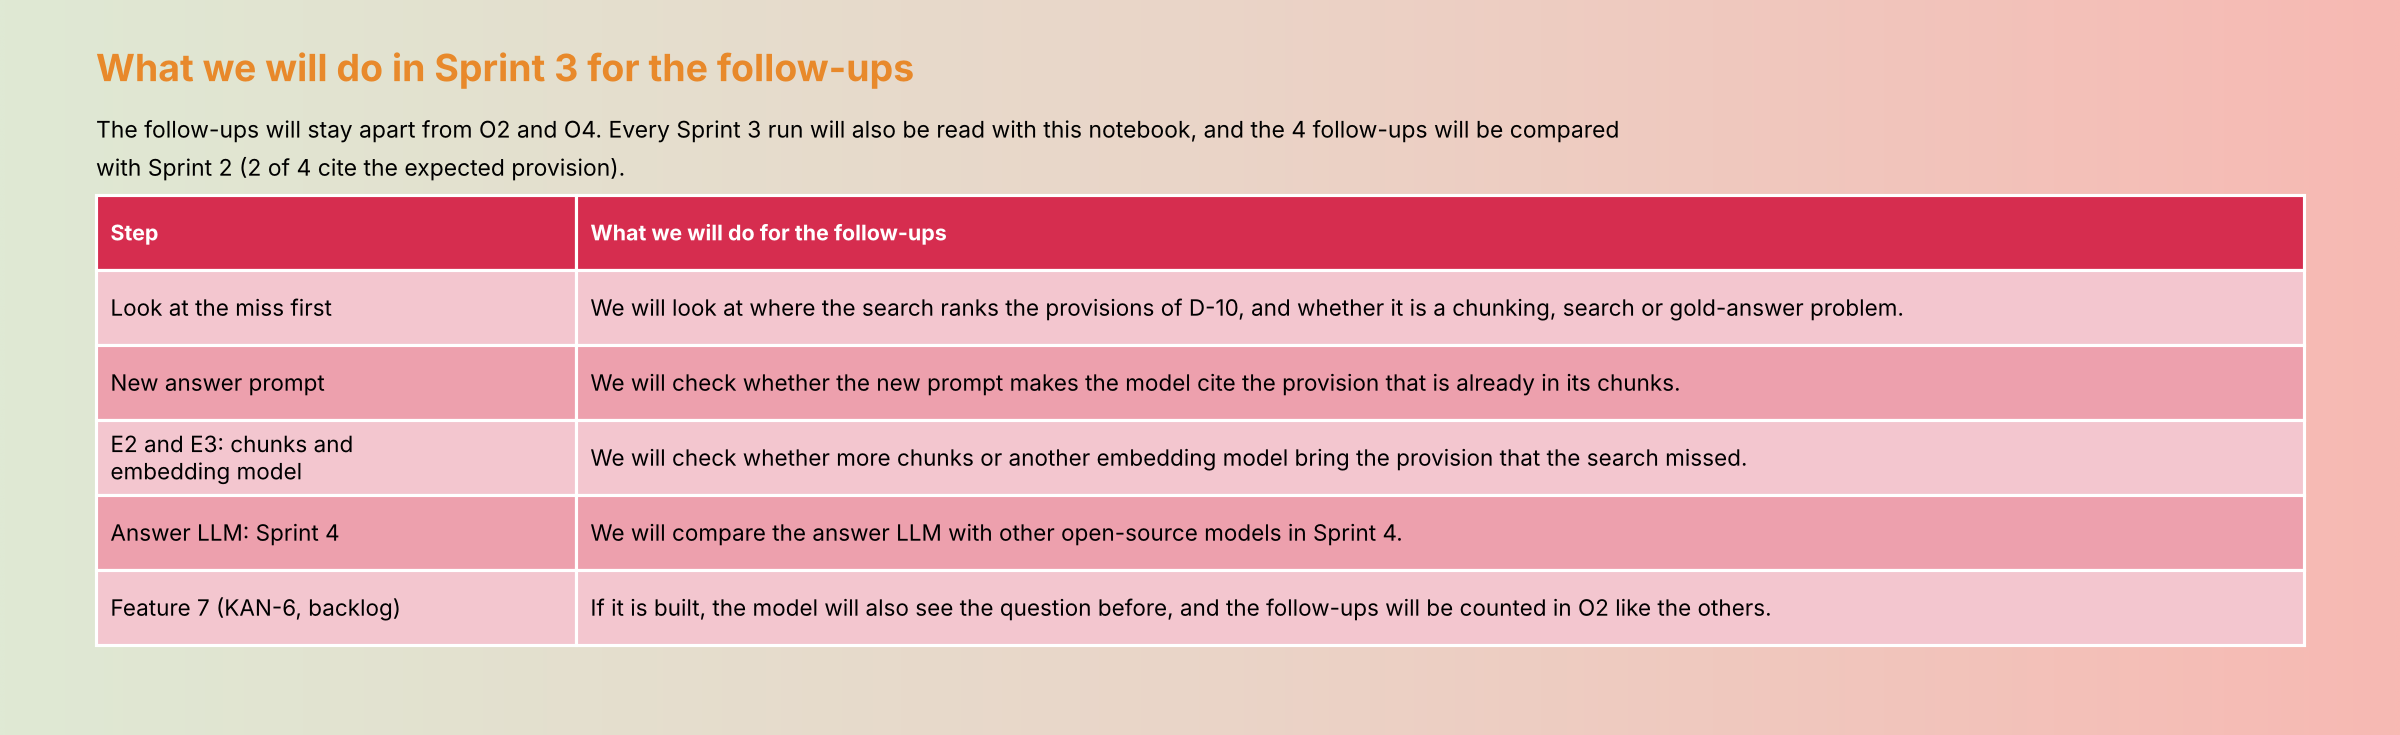

**In short:**
- **The task (KAN-228):** report the results of the 4 follow-up questions separately from the O2 and O4 results, as long as Feature 7 (KAN-6) is not built (KAN-65, test case TC-65.1).
- **The problem:** 4 `val` questions are follow-ups: A-02, B-03, C-03 and D-10. They only make sense after the question before them, for example A-02 *"And what must the people who oversee **it** be able to do?"* follows A-05. Our system answers every question alone and cannot remember the question before (that is Feature 7, not built yet). If these 4 questions were counted in O2 and O4, the system would look worse because of a missing feature, not because of its answers.
- **The method:** no new run. This notebook reads the saved answers of the Sprint 2 baseline (Llama-3.1-8B, 8 chunks) and checks each follow-up in two steps: (1) **search**: was a gold provision among the 8 chunks the model got? (2) **answer**: did the answer cite the expected provision (the O2 (a) check of `src/evaluation.ipynb`)?
- **The result:** 2 of 4 cite the expected provision (A-02, B-03). C-03 had its gold provision in the chunks but cited another one (answer model). D-10 had none of its gold provisions in the chunks (search). The O2 results without these 4 questions are in `src/evaluation.ipynb` (KAN-225).

**How to run:** set the answer file in section 1, then *Run All*. It only reads saved answers: no GPU, no Ollama, no API key. In Colab, the first cell downloads the repository.

In [1]:
import os, subprocess, sys
if "google.colab" in sys.modules:
    REPO = "/content/ELIZA_DI502_ORGANIZATION"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "https://github.com/ELIZA-DI502/ELIZA_DI502_ORGANIZATION.git", REPO], check=True)
    os.chdir(REPO + "/src")

## 1. Settings

In [2]:
ANSWERS = "../docs/eval/answers/val-with-retrieval-chunks.jsonl"     # saved answers of one system version, with their chunks
SPLIT = "val"
VERSION = "E1 baseline (Llama-3.1-8B, 8 chunks)"

## 2. The follow-up questions
The `type` column of the question set marks them; the `context` column names the question each one follows.

In [3]:
import csv, json
import pandas as pd
from citations import CITE, NO_ANSWER, norm          # citation check of KAN-128
from sources import shown_answer                       # the answer as the assistant shows it (check + sources line)
pd.set_option("display.max_colwidth", 200)

questions = {r["id"]: r for r in csv.DictReader(open("../docs/eval/eval-set-v1.csv", encoding="utf-8-sig")) if r["split"] == SPLIT}
follow_ups = [q for q in questions.values() if q["type"] == "follow-up"]
pd.DataFrame([{"id": q["id"], "follows": q["context"], "question": q["question"]} for q in follow_ups])

,id,follows,question
0,A-02,follows A-05,And what must the people who oversee it be able to do?
1,B-03,follows B-01,"Okay, and if we decide our grade calculator is not high-risk, do we still have to do anything before we launch it?"
2,C-03,follows C-02,What do we have to write down about all this before we start selling it to schools?
3,D-10,follows D-09,Our university customers' proctors might just accept every flag the tool shows. Which requirements are meant to stop that?


## 3. Did the answer cite the expected provision?
Two steps, kept apart:
- **retrieved:** the search gives the answer model **8 chunks** (top-k 8). *gold in the 8 chunks* says whether a gold provision is among them.
- **cited:** the answer model then writes the answer and cites only the provisions it uses, usually 1–3 of the 8. *expected provision cited* is the same check as O2 (a) in `src/evaluation.ipynb`: the answer cites a gold provision, or the paragraph that contains it (for gold Article 6(3)(a), "Article 6(3)" also counts).

So a miss has one of two causes: the gold provision was not among the 8 chunks (search), or it was there but the answer did not cite it (answer model).

In [4]:
answers = {r["id"]: r for r in map(json.loads, open(ANSWERS, encoding="utf-8"))}
ref_of = {c["chunk_id"]: c["ref"] for c in map(json.loads, open("../data/chunks.jsonl", encoding="utf-8"))}

rows = []
for q in follow_ups:
    a = answers[q["id"]]
    shown, sources, _ = shown_answer(a["answer"], a["chunks"])
    body = shown.split("\n\nSources (consolidated text of ")[0]
    cited = sorted({norm(c) for c in CITE.findall(body)})
    gold = [norm(ref_of[g]) for g in q["gold_ids"].split(";") if g.strip() in ref_of]
    retrieved = [c["chunk_id"] for c in a["chunks"]]
    rows.append({"id": q["id"], "follows": q["context"], "gold": "; ".join(gold),
                 "retrieved (8 chunks)": ", ".join(retrieved),
                 "gold in the 8 chunks": any(g.strip() in {r.split("#")[0] for r in retrieved} for g in q["gold_ids"].split(";")),
                 "cited": "; ".join(cited),
                 "expected provision cited": any(g.startswith(c) or c.startswith(g + "(") for c in cited for g in gold),   # a broader or a more detailed citation counts, as in src/evaluation.ipynb
                 "says it does not answer": NO_ANSWER in body,
                 "reference + version date (O2 (c))": bool(cited) and NO_ANSWER not in body and "Sources (consolidated text of " in shown})
result = pd.DataFrame(rows)

def why(r):
    # why the expected provision was not cited: the search did not bring it, or the answer model did not use it
    if r["expected provision cited"]:
        return "–"
    if not r["gold in the 8 chunks"]:
        return "search: no gold provision among the 8 chunks"
    if r["says it does not answer"]:
        return "answer model: gold in the chunks, but it says the text does not answer"
    return "answer model: gold in the chunks, but it cites another provision"

result["why it missed"] = result.apply(why, axis=1)
print(f"{VERSION}, {SPLIT}: expected provision cited in {int(result['expected provision cited'].sum())} of {len(result)} follow-up questions;",
      f"reference + version date in {int(result['reference + version date (O2 (c))'].sum())} of {len(result)}")
for _, r in result.iterrows():
    print(f"  {r['id']} ({r['follows']}): {'cited' if r['expected provision cited'] else 'not cited'}; {r['why it missed']}")
result

E1 baseline (Llama-3.1-8B, 8 chunks), val: expected provision cited in 2 of 4 follow-up questions; reference + version date in 4 of 4
  A-02 (follows A-05): cited; –
  B-03 (follows B-01): cited; –
  C-03 (follows C-02): not cited; answer model: gold in the chunks, but it cites another provision
  D-10 (follows D-09): not cited; search: no gold provision among the 8 chunks


,id,follows,gold,retrieved (8 chunks),gold in the 8 chunks,cited,expected provision cited,says it does not answer,reference + version date (O2 (c)),why it missed
0,A-02,follows A-05,article14(4),"ART14-4, ART14-1, ART13-1, ART14-3, ART50-1, ART14-2, ART4-1, ART13-3#2",True,article14(4),True,False,True,–
1,B-03,follows B-01,article6(4); article49(2),"ART6-4, ART6-3-1, ART16-f, ART16-h, ART49-2, ART9-6, ART9-8, ART10-6",True,article49(2); article6(4),True,False,True,–
2,C-03,follows C-02,article11(1),"ART11-1, ART12-3, ART6-4, ART11-2, ART3-9, ART10-3, ART13-1, ART49-2",True,article49(2); article6(4),False,False,True,"answer model: gold in the chunks, but it cites another provision"
3,D-10,follows D-09,article14(1); article14(4); article13(1); article12(1),"ART8-2, ART11-1, ART16-l, ART16-k, ART3-3, ART2-13, ART50-1, ART4-1",False,article16(l); article50(1),False,False,True,search: no gold provision among the 8 chunks


**Comment (Sprint 2 answers):** A-02 and B-03 cite the expected provision, and all 4 answers show their references with the version date (O2 (c)); none of the 4 is an application-date question, so O2 (d) does not apply. C-03 had its gold provision (Article 11(1)) among the 8 chunks, but the answer cited Article 49(2) and 6(4) instead: an answer-model miss. D-10 had none of its four gold provisions (Articles 12–14) among the 8 chunks: a search miss. The system answers each follow-up alone, without the question before. These results are not part of the O2 and O4 results until Feature 7 (KAN-6) is built.

## 4. The answers
To read why an answer missed, next to the question it follows.

In [5]:
pd.DataFrame([{"id": q["id"], "question": q["question"], "answer": answers[q["id"]]["answer"]} for q in follow_ups])

,id,question,answer
0,A-02,And what must the people who oversee it be able to do?,"Article 14(4) lists the tasks that the people who oversee the high-risk AI system must be able to do, including:\n\n* Properly understand the system's capacities and limitations (point a)\n* Remai..."
1,B-03,"Okay, and if we decide our grade calculator is not high-risk, do we still have to do anything before we launch it?","If you decide your grade calculator is not high-risk, Article 6(4) says you must document your assessment before launching it. You will also be subject to the registration obligation in Article 49..."
2,C-03,What do we have to write down about all this before we start selling it to schools?,Article 6(4) says that you must document your assessment before placing the system on the market or putting it into service if you consider it is not high-risk. Article 49(2) says that you must re...
3,D-10,Our university customers' proctors might just accept every flag the tool shows. Which requirements are meant to stop that?,"Article 50(1) requires that AI systems intended to interact directly with natural persons, such as your exam monitoring tool, are designed and developed to inform users that they are interacting w..."


## 5. Save
The table goes next to the answer file as `<answers>-follow-ups.csv`, for the technical summary.

In [6]:
out = ANSWERS.rsplit(".", 1)[0] + "-follow-ups.csv"
result.to_csv(out, index=False)
print("written:", out)

written: ../docs/eval/answers/val-with-retrieval-chunks-follow-ups.csv
